# SUPERCOMBO INFERENCE

### Basic imports

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from dataloader import load_transformed_video
#from common.transformations.camera import r
from utils import Calibration, draw_path, FULL_FRAME_SIZE, extract_preds, transform_img, transform_frames, medmodel_intrinsics
from matplotlib.patches import Patch
from model import load_inference_model
import cv2

### Basic params

In [3]:
X_IDXs = [
        0.,   0.1875,   0.75,   1.6875,   3.,   4.6875,
        6.75,   9.1875,  12.,  15.1875,  18.75,  22.6875,
        27.,  31.6875,  36.75,  42.1875,  48.,  54.1875,
        60.75,  67.6875,  75.,  82.6875,  90.75,  99.1875,
        108., 117.1875, 126.75, 136.6875, 147., 157.6875,
        168.75, 180.1875, 192.]

plot_img_width, plot_img_height = 640, 480 # can be reduced for wandb

fill_color_gt = [0,  255, 0]
line_color_gt = [255,255, 0]
fill_color_preds = [0,  0,255]
line_color_preds = [200,0,255]
laneline_colors = [(255, 0, 0), (0, 255, 0), (255, 0, 255), (0, 255, 255)]

def legend_color(color, opacity=0.3):
    return np.append(np.array(color)/255, opacity)

### Load transformed and raw RGB video

In [4]:
path_to_segment = '../videos/corrected_video_josu.avi'
ORIGINAL_MODEL = '../common/models/supercombo.onnx'

os.makedirs('outs', exist_ok=True)

seq_len = 200
input_frames, rgb_frames, yuv_frames, seq_len = load_transformed_video(path_to_segment, seq_len=seq_len)

### Load model

In [5]:
model_new, run_model_new = load_inference_model(ORIGINAL_MODEL)

### Run model

In [6]:
v_ego = 10 # km/h, simulación
steer_delay = 0.01 # s

lanelines_preds = []
road_edges_preds = []
path_preds = []

desire_data = np.array([0]).astype('float32')
desire_data.resize((1,8))

initial_state_data = np.array([0]).astype('float32')
initial_state_data.resize((1,2))

recurrent_state = np.zeros((1, 512), dtype=np.float32)

for t_idx in range(seq_len):
    if t_idx%(seq_len/10) == 0:
        print(f'{t_idx}/{seq_len} Frames proccesed')
        
    inputs = {
        'input_imgs': input_frames[t_idx:t_idx+1].numpy().astype(np.float32),
        'desire': desire_data,
        'traffic_convention': np.array([0, 1], dtype=np.float32).reshape(1, 2),
        'initial_state': recurrent_state
        }
    outs, recurrent_state = run_model_new(inputs)
    
    lanelines, road_edges, best_path = extract_preds(outs)[0]

    lanelines_preds.append(lanelines)
    road_edges_preds.append(road_edges)
    path_preds.append(best_path)
print(f'{seq_len}/{seq_len} Frames proccesed')

0/200 Frames proccesed
20/200 Frames proccesed
40/200 Frames proccesed
60/200 Frames proccesed
80/200 Frames proccesed
100/200 Frames proccesed
120/200 Frames proccesed
140/200 Frames proccesed
160/200 Frames proccesed
180/200 Frames proccesed
200/200 Frames proccesed


### Visualize 1 frame

##### Conf video 1

In [15]:
from matplotlib.animation import FuncAnimation, FFMpegWriter

t_idx = 6
camara_height = 1.591
car_width = 0.8
plot_width = 12
plot_height = plot_width * (FULL_FRAME_SIZE[1] / FULL_FRAME_SIZE[0])

rpy_calib_pred = np.array([0.0, -0.018, 0.0])
calibration = Calibration(rpy_calib_pred, plot_img_width=plot_img_width, plot_img_height=plot_img_height)

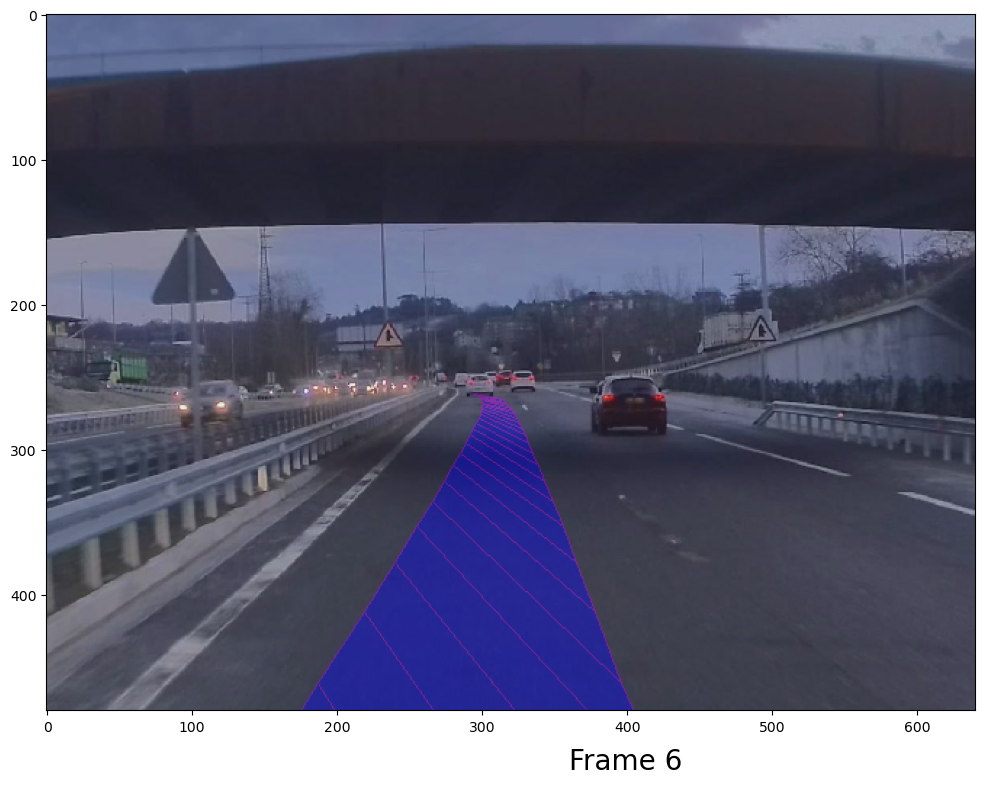

In [16]:
fig, ax = plt.subplots(1,1, figsize=(plot_width, plot_height))

img_plot = draw_path(lanelines_preds[t_idx], road_edges_preds[t_idx], path_preds[t_idx][0, :, :3], rgb_frames[t_idx], calibration, laneline_colors, fill_color=fill_color_preds, line_color=line_color_preds, height=camara_height, width=car_width)    

ax.clear()
txt = ax.text(plot_img_height-120, plot_img_width-120, f'Frame {t_idx}', fontsize=20)
plt_img = ax.imshow(img_plot)

### Create video

20/200 Frames proccesed
40/200 Frames proccesed
60/200 Frames proccesed
80/200 Frames proccesed
100/200 Frames proccesed
120/200 Frames proccesed
140/200 Frames proccesed
160/200 Frames proccesed
180/200 Frames proccesed
Video de 200 frames guardado en outs/output_video_largo.mp4


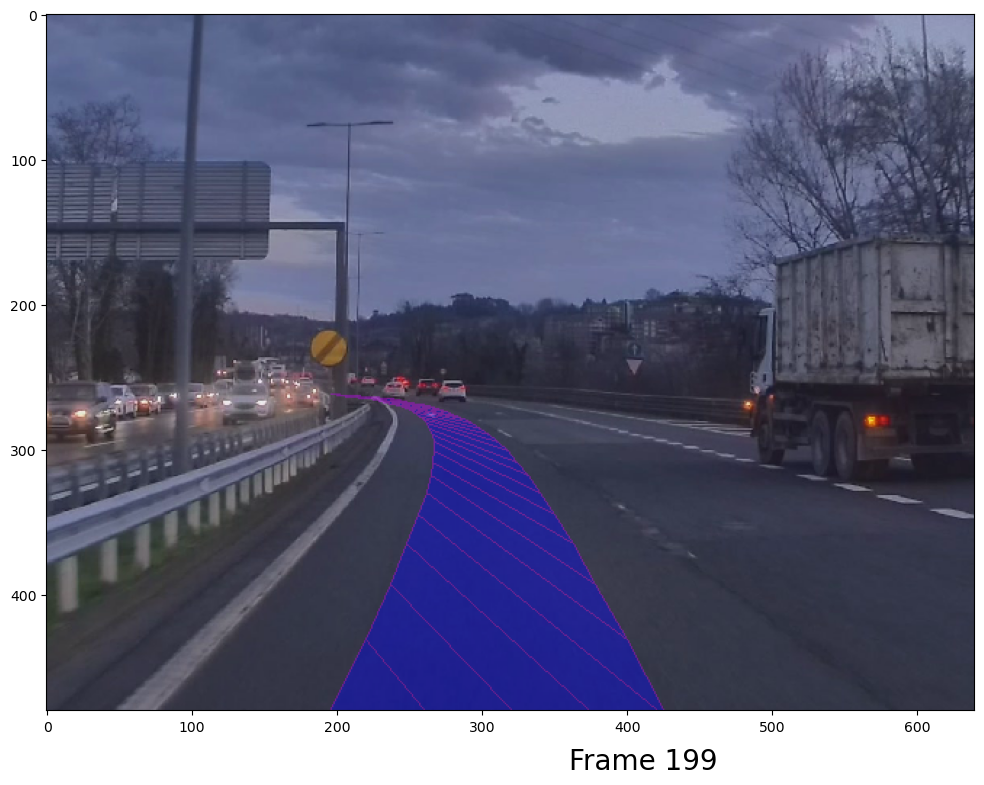

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter

video_file_name = 'output_video_largo.mp4' 
fig, ax = plt.subplots(1,1, figsize=(plot_width, plot_height))

def animate(t_idx):
    if t_idx%(seq_len/10) == 0 and t_idx != 0:
        print(f'{t_idx}/{seq_len} Frames proccesed')

    img_plot = draw_path(lanelines_preds[t_idx], road_edges_preds[t_idx], path_preds[t_idx][0, :, :3], rgb_frames[t_idx], calibration, laneline_colors, fill_color=fill_color_preds, line_color=line_color_preds, height=camara_height, width=car_width)    

    ax.clear()
    txt = ax.text(plot_img_height-120, plot_img_width-120, f'Frame {t_idx}', fontsize=20)
    plt_img = ax.imshow(img_plot)

    return txt, plt_img

anim = FuncAnimation(fig, animate, interval=1000/20, blit=True, repeat=True, frames=len(path_preds))  

# Guardar como video
writer = FFMpegWriter(fps=20, bitrate=2000)
anim.save(f"outs/{video_file_name}", writer=writer)

print(f"Video de {seq_len} frames guardado en outs/{video_file_name}")

### 5 path prediction

In [20]:
v_ego = 10 # km/h, simulación
steer_delay = 0.01 # s

lanelines_preds = []
road_edges_preds = []
path_preds = []

desire_data = np.array([0]).astype('float32')
desire_data.resize((1,8))

traffic_convention_data = np.array([0]).astype('float32')
traffic_convention_data.resize((1,512))

initial_state_data = np.array([0]).astype('float32')
initial_state_data.resize((1,2))

recurrent_state = np.zeros((1, 512), dtype=np.float32)

for t_idx in range(seq_len):
    if t_idx%(seq_len/10) == 0:
        print(f'{t_idx}/{seq_len} Frames proccesed')
        
    inputs = {
        'input_imgs': input_frames[t_idx:t_idx+1].numpy().astype(np.float32),
        'desire': desire_data,
        'traffic_convention': np.array([0, 1], dtype=np.float32).reshape(1, 2),
        'initial_state': recurrent_state
        }
    outs, recurrent_state = run_model_new(inputs)
    
    lanelines, road_edges, best_path = extract_preds(outs, best_plan_only=False)[0]

    lanelines_preds.append(lanelines)
    road_edges_preds.append(road_edges)
    path_preds.append(best_path)

0/200 Frames proccesed
20/200 Frames proccesed
40/200 Frames proccesed
60/200 Frames proccesed
80/200 Frames proccesed
100/200 Frames proccesed
120/200 Frames proccesed
140/200 Frames proccesed
160/200 Frames proccesed
180/200 Frames proccesed


#### 1 frame

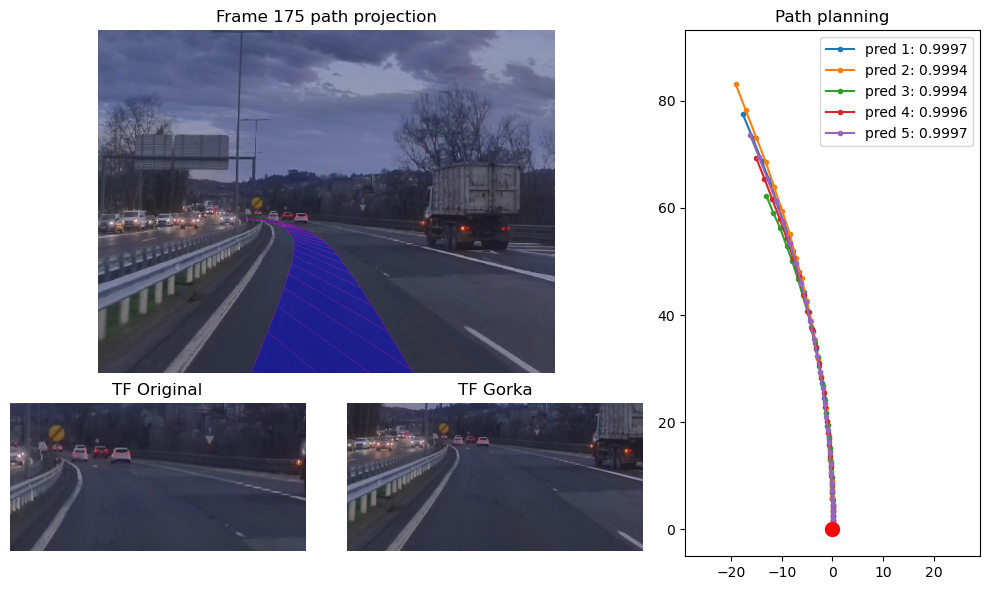

In [21]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
from utils import transform_img_gorka, transform_img, sigmoid

t_idx = 175
base_img = yuv_frames[t_idx]

plans_probs = path_preds[t_idx][1]

best_idx = np.argmax(plans_probs)
best_idx = 1
img_plot = draw_path(lanelines_preds[t_idx], road_edges_preds[t_idx], path_preds[t_idx][0][best_idx][0, :, :3], rgb_frames[t_idx], calibration, laneline_colors, fill_color=fill_color_preds, line_color=line_color_preds, height=camara_height, width=car_width)    
plans_probs = sigmoid(plans_probs)
fig = plt.figure(figsize=(10, 6))
gs = gridspec.GridSpec(3, 3, width_ratios=[1,1,1])  

ax1 = plt.subplot(gs[:2, :2]) 
ax1.clear()
ax1.set_title(f"Frame {t_idx} path projection")
plt_img = ax1.imshow(img_plot)
ax1.axis('off')

ax2 = plt.subplot(gs[2, 0])

# Aplicar la transformación
transformed_img = transform_img(
    base_img,
    top_hacks=False,
    yuv=True,
    output_size=(512, 256)
)

ax2.set_title("TF Original")
ax2.imshow(cv2.cvtColor(transformed_img, cv2.COLOR_YUV2RGB_I420) )
ax2.axis('off')

ax3 = plt.subplot(gs[2, 1])
ax3.axis('off')
transformed_img_gorka = transform_img_gorka(
    base_img,
    #augment_eulers=rvec,    
    #augment_trans=tvec,
    #from_intr=eon_intrinsics,
    #to_intr=medmodel_intrinsics, 
    top_hacks=False,
    yuv=True,
    output_size=(512, 256)
)
ax3.set_title("TF Gorka")
ax3.imshow(cv2.cvtColor(transformed_img_gorka, cv2.COLOR_YUV2RGB_I420) )

ax4 = plt.subplot(gs[:, 2])
#plan_probs = path_preds[t_idx][:, :, -1]
paths = path_preds[t_idx][0]
ylim = 0
xlim = 0
for i, path_full in enumerate(paths):
    path = path_full[0][:, :3]
    xlim = max(max(abs(path[:, 1]))+10, xlim)
    ylim = max(max(abs(path[:, 0]))+10, ylim)
    prob = np.round(plans_probs[i], 4)
    ax4.plot(path[:, 1], path[:, 0], '.-', label=f"pred {i+1}: {str(prob)}", alpha = plans_probs[i])

ax4.set_xlim([-xlim, xlim])
ax4.set_ylim([-5, ylim])

ax4.plot(0,0,'o', color='red', markersize = 10)
ax4.set_title("Path planning")
ax4.legend()

# Ajustar el layout
plt.tight_layout()
plt.show()


#### Generate video

0/1000 frames procesed
100/1000 frames procesed
200/1000 frames procesed
300/1000 frames procesed
400/1000 frames procesed
500/1000 frames procesed
600/1000 frames procesed
700/1000 frames procesed
800/1000 frames procesed
900/1000 frames procesed
Video guardado en outs/full_output_video_gps.mp4


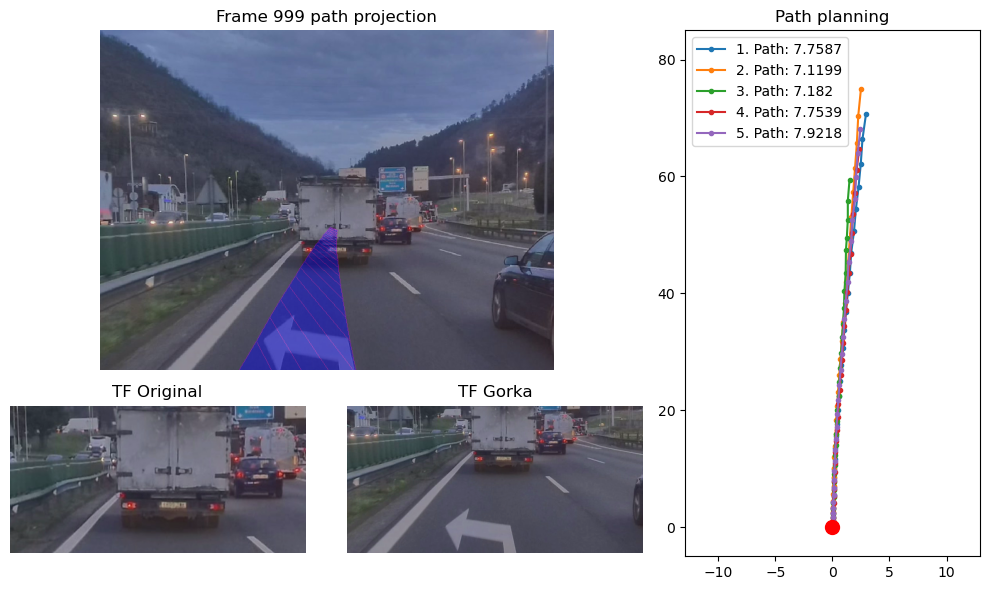

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import cv2
import matplotlib.animation as animation
from utils import transform_img_gorka, transform_img


# Parámetros del video
output_video_path = "outs/full_output_video_gps.mp4"
fps = 30  # Frames por segundo
frame_width = 800  # Ajusta según sea necesario
frame_height = 600  # Ajusta según sea necesario

# Inicializar el video writer
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(output_video_path, fourcc, fps, (frame_width, frame_height))

fig = plt.figure(figsize=(10, 6))
gs = gridspec.GridSpec(3, 3, width_ratios=[1,1,1])

ax1 = plt.subplot(gs[:2, :2])
ax2 = plt.subplot(gs[2, 0])
ax3 = plt.subplot(gs[2, 1])
ax4 = plt.subplot(gs[:, 2])

def update_plot(t_idx):
    global out
    if t_idx % 100 == 0:
        print(f"{t_idx}/{seq_len} frames procesed")
        
    ax1.clear()
    ax2.clear()
    ax3.clear()
    ax4.clear()
    
    base_img = yuv_frames[t_idx]

    plans_probs = path_preds[t_idx][1]
    best_idx = np.argmax(plans_probs)
    img_plot = draw_path(lanelines_preds[t_idx], road_edges_preds[t_idx], path_preds[t_idx][0][best_idx][0, :, :3], rgb_frames[t_idx], calibration, laneline_colors, fill_color=fill_color_preds, line_color=line_color_preds, height=camara_height, width=car_width)
    
    ax1.set_title(f"Frame {t_idx} path projection")
    ax1.imshow(img_plot)
    ax1.axis('off')
    
    transformed_img = transform_img(base_img, top_hacks=False, yuv=True, output_size=(512, 256))
    ax2.set_title("TF Original")
    ax2.imshow(cv2.cvtColor(transformed_img, cv2.COLOR_YUV2RGB_I420))
    ax2.axis('off')
    
    transformed_img_gorka = transform_img_gorka(base_img, top_hacks=False, yuv=True, output_size=(512, 256))
    ax3.set_title("TF Gorka")
    ax3.imshow(cv2.cvtColor(transformed_img_gorka, cv2.COLOR_YUV2RGB_I420))
    ax3.axis('off')
    
    ax4.set_title("Path planning")
    paths = path_preds[t_idx][0]
    xlim, ylim = 0, 0
    for i, path_full in enumerate(paths):
        path = path_full[0][:, :3]
        xlim = max(max(abs(path[:, 1]))+10, xlim)
        ylim = max(max(abs(path[:, 0]))+10, ylim)
        prob = np.round(plans_probs[i], 4)
        ax4.plot(path[:, 1], path[:, 0], '.-', label=f"{i+1}. Path: {str(prob)}")
    ax4.set_xlim([-xlim, xlim])
    ax4.set_ylim([-5, ylim])
    ax4.plot(0, 0, 'o', color='red', markersize=10)
    ax4.legend()
    
    plt.tight_layout()
    fig.canvas.draw()
    frame = np.array(fig.canvas.renderer.buffer_rgba())
    frame = cv2.cvtColor(frame, cv2.COLOR_RGBA2BGR)
    frame_resized = cv2.resize(frame, (frame_width, frame_height))
    out.write(frame_resized)

# Generar el video procesando todos los frames
for t_idx in range(len(yuv_frames)-1):
    update_plot(t_idx)

# Liberar recursos
out.release()
print(f"Video guardado en {output_video_path}")


### Metrics visualization

In [22]:
import json
import numpy as np
import pandas as pd

# Load the JSON file
file_path = "/home/VICOMTECH/gortiz/Proyectos/Mendi4U/openpilot-pipeline/rtmaps/metrics.json"
with open(file_path, "r") as file:
    data = json.load(file)
    
# Organize results by range
ranges = ["0-10m", "10-20m", "20-30m", "30-40m", "+40m"]
stats_by_range = {r: {"mean_error": [], "max_error": [], "std_error": [], "AP@0.5": [], "AP@1": [], "AP@2": []} for r in ranges}

# Populate stats_by_range dictionary
for entry in data["errors_by_range"]:
    for r in ranges:
        stats_by_range[r]["mean_error"].append(entry[r]["mean_error"])
        stats_by_range[r]["max_error"].append(entry[r]["max_error"])
        stats_by_range[r]["std_error"].append(entry[r]["std_error"])
        stats_by_range[r]["AP@0.5"].append(entry[r]["hit_rates"]["AP@0.5"])
        stats_by_range[r]["AP@1"].append(entry[r]["hit_rates"]["AP@1"])
        stats_by_range[r]["AP@2"].append(entry[r]["hit_rates"]["AP@2"])

# Compute required statistics for each range
results = {}
for r in ranges:
    results[r] = {
        "mean_mean_error": np.mean(stats_by_range[r]["mean_error"]),
        "max_max_error": np.max(stats_by_range[r]["max_error"]),
        "mean_std_error": np.mean(stats_by_range[r]["std_error"]),
        "mean_AP@0.5": np.mean(stats_by_range[r]["AP@0.5"]),
        "mean_AP@1": np.mean(stats_by_range[r]["AP@1"]),
        "mean_AP@2": np.mean(stats_by_range[r]["AP@2"])
    }

df_results = pd.DataFrame.from_dict(results, orient="index")
# Mostrar la tabla en Jupyter Notebook
from IPython.display import display
display(df_results)

,mean_mean_error,max_max_error,mean_std_error,mean_AP@0.5,mean_AP@1,mean_AP@2
0-10m,0.365806,1.516990,0.169081,0.769971,0.964932,1.000000
10-20m,1.086576,2.825050,0.192666,0.137963,0.576852,0.884259
20-30m,1.843220,5.180393,0.228150,0.061111,0.224074,0.623148
30-40m,2.810147,8.565139,0.280094,0.031481,0.080556,0.286111
+40m,15.019936,54.455273,9.000945,0.004945,0.010605,0.027476
